# Study 2: Spillover and reward formulation screen

This notebook checks spillover with uneven pollution stocks and compares reward equations on the same action outcomes. It uses temporary copies of the checked-in environment configuration; it does not change the environment source or train agents. Notebook 16 showed that the source linear emissions equation can reach and maintain EDI 100 under a strong fixed policy.

A useful formulation should support high EDI, survive, keep pollution low without driving it to zero, and make spillover visible in regional exposure.

## 1. Spillover from an 85-unit hotspot

Compare no transport, source transport shares, a fixed 60% share, and load-amplified transfer: `tau(S) = tau_source + (0.70 - tau_source) * (max_stock / limit)^2`. One pollutant starts at 85 in region 0 and 10 in the neighbors; all regions remain at EDI 100 and use high prevention. Transfer redistributes mass before cleanup. The rates are sensitivity settings, not calibrated physical laws.

## 2. Compare reward equations on the same actions

The source reward is `development_gain + (income - income_base) / ongoing_income_reward_scale - pollution_damage`. It does not directly subtract mitigation or development spending, so the reward can favor costly cleanup without accounting for the currency it consumes.

The candidate reward is `gain/10 + 0.75 * EDI_next/100 + income_increment/100 - lambda * damage - 100 * max(0, max_pollutant_pressure - 0.25)^2 - 0.05 * development_cost/100 - 0.50 * mitigation_cost/100 - 10 * failure - 5 * invalid_action`. Development cost has a smaller direct penalty because lost currency already limits growth; mitigation spending remains explicit. The risk term uses the highest pollutant load relative to its limit, so high soil pollution cannot be hidden by moderate weighted GPI.

In [1]:
from copy import deepcopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from study_2_economic_sustainability.config import EnvironmentConfig
from study_2_economic_sustainability.environment import ACTION_NAMES, EconomicSustainabilityEnvironment, action_parts

In [2]:
def run_spillover(pollutant, case, steps=30):
    config = deepcopy(BASE)
    env = EconomicSustainabilityEnvironment(config=config)
    env.reset(9100)

    env.development_indices = (100,) * len(REGIONS)
    env.currency_balances = (1_000_000.0,) * len(REGIONS)

    env.pollutant_loads = {}

    for p in POLLUTANTS:
        env.pollutant_loads[p] = (10.0,) * len(REGIONS)

    env.pollutant_loads[pollutant] = (85.0, 10.0, 10.0, 10.0)
    env._update_indices()

    rows = []
    moved_emissions = 0.0
    moved_stock = 0.0
    failed = False

    for step in range(1, steps + 1):
        fractions = {}

        for p in POLLUTANTS:
            source = BASE.transport_fractions[p]
            maximum_load = max(env.pollutant_loads[p])
            limit = config.pollution_limits[p]
            severity = np.clip(maximum_load / limit, 0, 1)

            if case == "none":
                fractions[p] = 0.0

            elif case == "source":
                fractions[p] = source

            elif case == "fixed_0.60":
                fractions[p] = 0.60

            else:
                fractions[p] = source + (0.70 - source) * severity ** 2

        config.transport_fractions = fractions

        actions = [HIGH_PREVENTION] * len(REGIONS)
        _, _, terminated, truncated, info = env.step(actions)

        failed = failed or terminated
        moved_emissions += sum(info["incoming_emissions"][pollutant])
        moved_stock += sum(info["incoming_pollution"][pollutant])

        row = {
            "step": step,
            "hotspot": env.pollutant_loads[pollutant][0],
            "neighbors": np.mean(env.pollutant_loads[pollutant][1:3]),
            "max_stock": max(env.pollutant_loads[pollutant]),
            "GPI": env.global_pollution_index,
        }

        rows.append(row)

        if terminated or truncated:
            break

    trace = pd.DataFrame(rows)

    summary = {
        "case": case,
        "pollutant": pollutant,
        "neighbor_step_1": trace.iloc[0]["neighbors"],
        "neighbor_final": trace.iloc[-1]["neighbors"],
        "hotspot_final": trace.iloc[-1]["hotspot"],
        "peak_stock": trace["max_stock"].max(),
        "mean_GPI": trace["GPI"].mean(),
        "transferred_emissions": moved_emissions,
        "transferred_recovered_stock": moved_stock,
        "survived": not failed,
    }

    return summary, trace

In [3]:
def reward_action(state, stocks, action):
    config = deepcopy(BASE)
    env = EconomicSustainabilityEnvironment(reward_mode="local", config=config, reward_formula="original")
    env.reset(1234)

    env.development_indices = (60,) * len(REGIONS)
    env.currency_balances = (1000.0,) * len(REGIONS)

    env.pollutant_loads = {}

    for pollutant in POLLUTANTS:
        env.pollutant_loads[pollutant] = tuple(stocks)

    env._update_indices()

    actions = [MEDIUM_PREVENTION] * len(REGIONS)
    actions[0] = action

    _, _, _, _, info = env.step(actions)

    row = {
        "state": state,
        "action": ACTION_NAMES[action],
        "EDI_gain": info["development_gains"][0],
        "EDI_after": info["development_indices"][0],
        "GPI_after": info["regional_pollution_indices"][0],
        "damage_after": info["pollution_damage"][0],
        "cost": info["costs_paid"][0],
        "source_local": info["local_rewards"][0],
        "source_global": info["global_reward"],
        "source_mixed": info["mixed_rewards"][0],
    }

    for weight in lambdas:
        values = []

        for region in REGIONS:
            damage = info["pollution_damage"][region]

            max_pressure = 0.0

            for pollutant in POLLUTANTS:
                load = info["pollutant_loads"][pollutant][region]
                limit = config.pollution_limits[pollutant]
                pressure = load / limit

                max_pressure = max(max_pressure, pressure)

            failed = False

            for failed_region, pollutant in info["failed_regions"]:
                if failed_region == region:
                    failed = True
                    break

            edi_gain = info["development_gains"][region]
            edi_after = info["development_indices"][region]
            income = info["income"][region]

            value = (edi_gain / 10 + 0.75 * edi_after / 100 + (income - config.income_base) / 100)
            risk = 100 * max(0, max_pressure - 0.25) ** 2

            development_cost = info["development_costs_paid"][region]
            prevention_cost = info["prevention_costs_paid"][region]
            cleanup_cost = info["cleanup_costs_paid"][region]
            mitigation_cost = prevention_cost + cleanup_cost

            value -= (weight * damage + risk + 0.05 * development_cost / 100 + 0.50 * mitigation_cost / 100 + 10 * failed)

            if info["invalid_attempts"][region]:
                value -= 5

            values.append(value)

        mean_value = np.mean(values)

        row[f"balanced_{weight}_local"] = values[0]
        row[f"balanced_{weight}_global"] = mean_value
        row[f"balanced_{weight}_mixed"] = 0.7 * values[0] + 0.3 * mean_value

    return row

In [4]:

def score_objective(info, config, objective, region):
    if objective == "source_local":
        return info["local_rewards"][region]

    elif objective == "source_global":
        return info["global_reward"]

    elif objective == "source_mixed":
        return info["mixed_rewards"][region]

    weight = float(objective.split("_")[1])
    values = []

    for index in REGIONS:
        max_pressure = 0.0

        for pollutant in POLLUTANTS:
            load = info["pollutant_loads"][pollutant][index]
            limit = config.pollution_limits[pollutant]
            pressure = load / limit

            max_pressure = max(max_pressure, pressure)

        damage = info["pollution_damage"][index]

        failed_here = False

        for failed_region, pollutant in info["failed_regions"]:
            if failed_region == index:
                failed_here = True
                break

        edi_gain = info["development_gains"][index]
        edi_after = info["development_indices"][index]
        income = info["income"][index]

        value = (edi_gain / 10 + 0.75 * edi_after / 100 + (income - config.income_base) / 100)

        risk = 100 * max(0, max_pressure - 0.25) ** 2

        development_cost = info["development_costs_paid"][index]
        prevention_cost = info["prevention_costs_paid"][index]
        cleanup_cost = info["cleanup_costs_paid"][index]
        mitigation_cost = prevention_cost + cleanup_cost

        value -= (weight * damage + risk + 0.05 * development_cost / 100 + 0.50 * mitigation_cost / 100 + 10 * failed_here)

        if info["invalid_attempts"][index]:
            value -= 5

        values.append(value)

    mean_value = np.mean(values)
    return 0.7 * values[region] + 0.3 * mean_value

In [5]:
def greedy_actions(env, objective):
    chosen = []
    for region in REGIONS:
        scores = []
        for action in range(len(ACTION_NAMES)):
            trial = deepcopy(env); candidate = [MEDIUM_PREVENTION] * len(REGIONS); candidate[region] = action
            _, _, _, _, info = trial.step(candidate)
            scores.append(score_objective(info, trial.config, objective, region))
        chosen.append(int(np.argmax(scores)))
    return chosen

In [6]:

def run_greedy_episode(objective, seed):
    config = deepcopy(BASE)
    env = EconomicSustainabilityEnvironment(config=config, reward_formula="original")
    env.reset(seed)

    gpi_values = [env.global_pollution_index]
    peak_pressure = 0.0
    mitigation_spending = 0.0
    development_spending = 0.0

    failed = False
    failure_step = np.nan
    failure_pollutants = set()

    for step in range(config.episode_steps):
        actions = greedy_actions(env, objective)
        _, _, terminated, truncated, info = env.step(actions)

        prevention_spending = sum(info["prevention_costs_paid"])
        cleanup_spending = sum(info["cleanup_costs_paid"])

        mitigation_spending += prevention_spending + cleanup_spending
        development_spending += sum(info["development_costs_paid"])

        gpi_values.append(env.global_pollution_index)

        for pollutant in POLLUTANTS:
            for region in REGIONS:
                load = env.pollutant_loads[pollutant][region]
                limit = config.pollution_limits[pollutant]
                pressure = load / limit

                peak_pressure = max(peak_pressure, pressure)

        if terminated:
            failed = True
            failure_step = env.step_count

            for region, pollutant in info["failed_regions"]:
                failure_pollutants.add(pollutant)

            break

        if truncated:
            break

    row = {
        "objective": objective,
        "seed": seed,
        "success_EDI_100": not failed and min(env.development_indices) >= 100,
        "survived": not failed,
        "final_EDI_mean": np.mean(env.development_indices),
        "final_EDI_min": min(env.development_indices),
        "mean_GPI": np.mean(gpi_values),
        "peak_GPI": max(gpi_values),
        "peak_pressure": peak_pressure,
        "mitigation_spending": mitigation_spending,
        "development_spending": development_spending,
        "failure_step": failure_step,
        "failure_pollutants": ", ".join(sorted(failure_pollutants)),
    }

    return row

In [7]:
BASE = EnvironmentConfig()
POLLUTANTS = BASE.pollutants
REGIONS = BASE.regions

ACTION_IDS = {}

for index, name in enumerate(ACTION_NAMES):
    ACTION_IDS[name] = index

HIGH_PREVENTION = ACTION_IDS["maintain_prevent_high"]
MEDIUM_PREVENTION = ACTION_IDS["maintain_prevent_medium"]


In [8]:
cases = ("none", "source", "fixed_0.60", "load_amplified")

spillover_rows = []
spillover_traces = []

for pollutant in POLLUTANTS:
    for case in cases:
        result, trace = run_spillover(pollutant, case)

        spillover_rows.append(result)

        trace["pollutant"] = pollutant
        trace["case"] = case

        spillover_traces.append(trace)

spillover_table = pd.DataFrame(spillover_rows)
spillover_trajectory = pd.concat(spillover_traces, ignore_index=True)

display(spillover_table.round(3))

,case,pollutant,neighbor_step_1,neighbor_final,hotspot_final,peak_stock,mean_GPI,transferred_emissions,transferred_recovered_stock,survived
0,none,air,6.900,4.637,4.637,47.588,9.286,0.000,0.000,True
1,source,air,13.003,4.637,4.637,35.381,9.278,99.000,94.386,True
2,fixed_0.60,air,19.106,4.637,4.637,23.175,9.275,198.000,188.196,True
3,load_amplified,air,18.882,4.637,4.637,23.623,9.275,102.772,111.625,True
4,none,water,10.134,11.259,19.337,82.119,11.600,0.000,0.000,True
5,source,water,24.531,12.233,12.233,53.325,10.930,60.000,763.318,True
6,fixed_0.60,water,31.729,12.220,12.220,38.928,10.910,90.000,1140.245,True
7,load_amplified,water,32.332,12.221,12.221,37.722,10.911,62.687,807.607,True
8,none,soil,10.441,20.631,87.713,87.713,13.470,0.000,0.000,True
9,source,soil,14.173,34.008,35.266,77.617,13.059,7.500,374.873,True


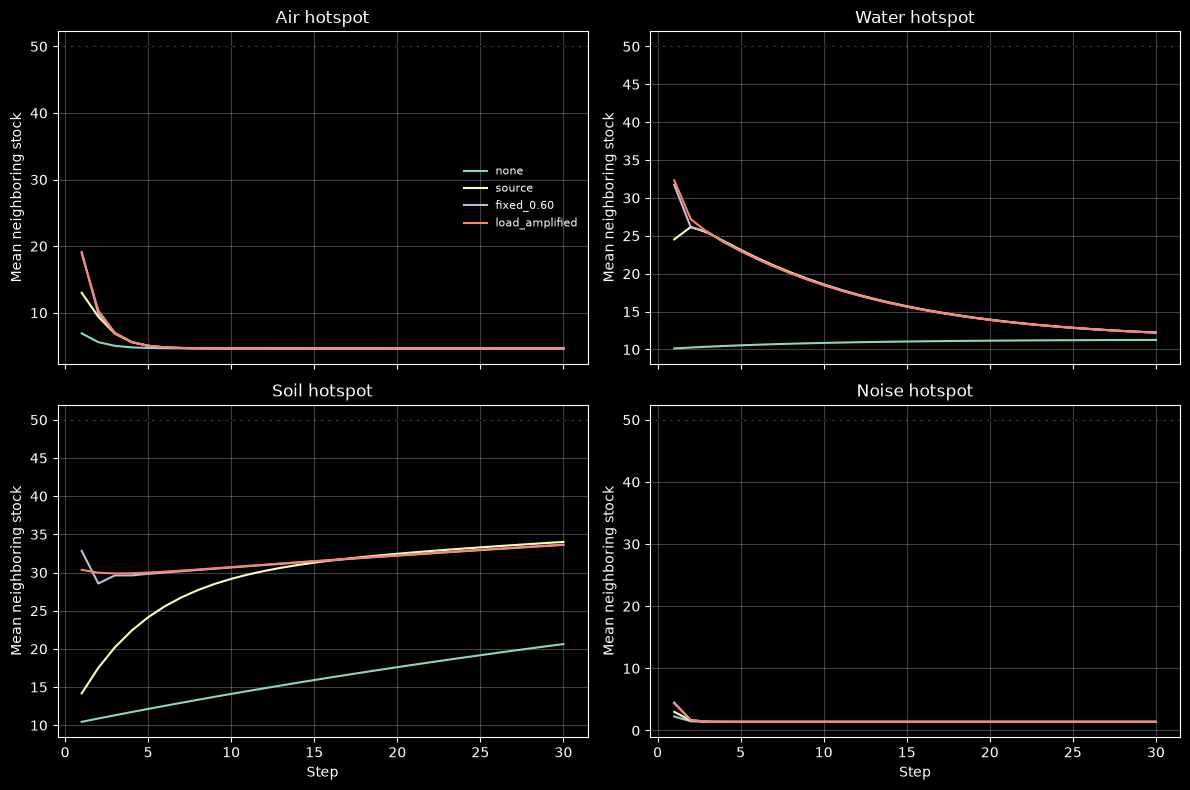

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

for axis, pollutant in zip(axes.flat, POLLUTANTS):
    subset = spillover_trajectory[spillover_trajectory["pollutant"] == pollutant]

    for case in cases:
        curve = subset[subset["case"] == case]
        axis.plot(curve["step"], curve["neighbors"], label=case)

    axis.axhline(50, color="black", linestyle="--", linewidth=1)
    axis.set_title(pollutant.title() + " hotspot")
    axis.set_ylabel("Mean neighboring stock")
    axis.grid(alpha=0.25)

axes[1, 0].set_xlabel("Step")
axes[1, 1].set_xlabel("Step")
axes[0, 0].legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

In [10]:
neighbor_table = spillover_table.pivot(index="pollutant", columns="case", values="neighbor_step_1")

neighbor_table["source_minus_none"] = neighbor_table["source"] - neighbor_table["none"]

display(neighbor_table[["none", "source", "source_minus_none"]].round(3))

case,none,source,source_minus_none
pollutant,,,
air,6.900,13.003,6.103
noise,2.250,3.000,0.750
soil,10.441,14.173,3.732
water,10.134,24.531,14.397


In [11]:
# Reward formula adds a smooth max-pollutant risk cost above 25% of its limit. Compare source rewards and lambda values 1.0, 1.5, and 2.0.
reward_states = {"low": (10, 10, 10, 10), "moderate": (35, 35, 35, 35), "hotspot": (65, 15, 15, 15)}
lambdas = (1.0, 1.5, 2.0)

reward_rows = []

for state, stocks in reward_states.items():
    for action in range(len(ACTION_NAMES)):
        result = reward_action(state, stocks, action)
        reward_rows.append(result)

reward_table = pd.DataFrame(reward_rows)

In [12]:
objectives = ("source_local", "source_global", "source_mixed", "balanced_1.0_mixed", "balanced_1.5_mixed", "balanced_2.0_mixed")
best_rows = []

for state in reward_states:
    subset = reward_table[reward_table["state"] == state]

    for objective in objectives:
        best = subset.sort_values([objective, "cost"], ascending=[False, True]).iloc[0]

        row = {
            "state": state,
            "objective": objective,
            "best_action": best["action"],
            "EDI_gain": best["EDI_gain"],
            "GPI_after": best["GPI_after"],
            "cost": best["cost"],
        }

        best_rows.append(row)

best_actions_table = pd.DataFrame(best_rows)
display(best_actions_table.round(3))

,state,objective,best_action,EDI_gain,GPI_after,cost
0,low,source_local,develop_clean_high,5,1.472,180.0
1,low,source_global,develop_clean_high,5,1.472,180.0
2,low,source_mixed,develop_clean_high,5,1.472,180.0
3,low,balanced_1.0_mixed,develop_none,5,10.554,100.0
4,low,balanced_1.5_mixed,develop_none,5,10.554,100.0
5,low,balanced_2.0_mixed,develop_none,5,10.554,100.0
6,moderate,source_local,develop_clean_high,5,19.361,180.0
7,moderate,source_global,develop_clean_high,5,19.361,180.0
8,moderate,source_mixed,develop_clean_high,5,19.361,180.0
9,moderate,balanced_1.0_mixed,develop_clean_high,5,19.361,180.0


In [13]:
print("Action scores under moderate pollution:")
moderate_scores = reward_table[reward_table["state"] == "moderate"]
display(moderate_scores[["action", "EDI_gain", "GPI_after", "damage_after", "cost", "source_local", "balanced_1.5_mixed", "balanced_2.0_mixed"]].round(3))

Action scores under moderate pollution:


,action,EDI_gain,GPI_after,damage_after,cost,source_local,balanced_1.5_mixed,balanced_2.0_mixed
14,maintain_none,0,27.948,0.279,0.0,2.721,-0.892,-1.030
15,develop_none,5,27.948,0.279,100.0,7.721,-0.514,-0.652
16,maintain_prevent_low,0,27.146,0.271,10.0,2.729,-0.855,-0.990
17,maintain_prevent_medium,0,26.343,0.263,25.0,2.737,-0.841,-0.972
18,maintain_prevent_high,0,25.541,0.255,50.0,2.745,-0.867,-0.995
19,maintain_clean_low,0,26.169,0.262,15.0,2.738,-0.684,-0.815
20,maintain_clean_medium,0,23.501,0.235,40.0,2.765,-0.449,-0.570
21,maintain_clean_high,0,19.361,0.194,80.0,2.806,-0.238,-0.343
22,develop_prevent_low,5,27.146,0.271,110.0,7.729,-0.477,-0.612
23,develop_prevent_medium,5,26.343,0.263,125.0,7.737,-0.463,-0.594


In [14]:
# Test reward incentives over full episodes using a fixed, non-learning one-step lookahead rule.
episode_objectives = ("source_mixed", "balanced_0.5_mixed", "balanced_0.75_mixed", "balanced_1.0_mixed", "balanced_1.5_mixed", "balanced_2.0_mixed")

episode_rows = []

for objective in episode_objectives:
    for seed in range(31, 36):
        result = run_greedy_episode(objective, seed)
        episode_rows.append(result)

episode_results = pd.DataFrame(episode_rows)

episode_summary = episode_results.groupby("objective").agg(
    runs=("seed", "count"),
    success_rate=("success_EDI_100", "mean"),
    survival_rate=("survived", "mean"),
    final_EDI=("final_EDI_mean", "mean"),
    mean_GPI=("mean_GPI", "mean"),
    peak_pressure=("peak_pressure", "mean"),
    mitigation_spending=("mitigation_spending", "mean"),
    development_spending=("development_spending", "mean")
).reset_index()

display(episode_summary.round(3))

display(episode_results[["objective", "seed", "success_EDI_100", "final_EDI_min", "mean_GPI", "peak_pressure", "failure_step", "failure_pollutants"]].round(3))

,objective,runs,success_rate,survival_rate,final_EDI,mean_GPI,peak_pressure,mitigation_spending,development_spending
0,balanced_0.5_mixed,5,1.0,1.0,100.0,18.245,0.300,14645.0,10000.0
1,balanced_0.75_mixed,5,1.0,1.0,100.0,18.006,0.301,14724.0,10000.0
2,balanced_1.0_mixed,5,1.0,1.0,100.0,17.808,0.299,14756.0,10000.0
3,balanced_1.5_mixed,5,1.0,1.0,100.0,17.349,0.296,14894.0,10000.0
4,balanced_2.0_mixed,5,1.0,1.0,100.0,16.996,0.295,14956.0,10000.0
5,source_mixed,5,0.0,1.0,29.5,0.696,0.071,27981.0,1300.0


,objective,seed,success_EDI_100,final_EDI_min,mean_GPI,peak_pressure,failure_step,failure_pollutants
0,source_mixed,31,False,10,0.702,0.102,NaN,
1,source_mixed,32,False,10,0.530,0.057,NaN,
2,source_mixed,33,False,20,0.752,0.043,NaN,
3,source_mixed,34,False,10,0.724,0.085,NaN,
4,source_mixed,35,False,10,0.773,0.068,NaN,
5,balanced_0.5_mixed,31,True,100,18.295,0.302,NaN,
6,balanced_0.5_mixed,32,True,100,18.244,0.303,NaN,
7,balanced_0.5_mixed,33,True,100,18.206,0.296,NaN,
8,balanced_0.5_mixed,34,True,100,18.292,0.302,NaN,
9,balanced_0.5_mixed,35,True,100,18.189,0.300,NaN,


## 3. Matched-seed validation of the promising reward weights

The five-seed screen favored the balanced reward with `lambda=2.0`. Validate it against `lambda=1.5` over 20 new matched seeds. Both use the same source equations, fixed lookahead policy, and environmental seed for each pair. This checks whether the lower GPI at lambda 2 persists beyond the initial screen.

In [15]:
VALIDATION_SEEDS = tuple(range(101, 121))
VALIDATION_OBJECTIVES = ("balanced_1.5_mixed", "balanced_2.0_mixed")

validation_rows = []

for seed in VALIDATION_SEEDS:
    for objective in VALIDATION_OBJECTIVES:
        result = run_greedy_episode(objective, seed)
        validation_rows.append(result)

validation_results = pd.DataFrame(validation_rows)

In [16]:
validation_summary = validation_results.groupby("objective").agg(
    matched_runs=("seed", "count"),
    success_rate=("success_EDI_100", "mean"),
    survival_rate=("survived", "mean"),
    final_EDI=("final_EDI_mean", "mean"),
    mean_GPI=("mean_GPI", "mean"),
    peak_pressure_mean=("peak_pressure", "mean"),
    peak_pressure_max=("peak_pressure", "max"),
    mitigation_spending=("mitigation_spending", "mean")
).reset_index()

display(validation_summary.round(3))

,objective,matched_runs,success_rate,survival_rate,final_EDI,mean_GPI,peak_pressure_mean,peak_pressure_max,mitigation_spending
0,balanced_1.5_mixed,20,1.0,1.0,100.0,17.196,0.295,0.304,15088.25
1,balanced_2.0_mixed,20,1.0,1.0,100.0,16.949,0.293,0.302,15132.50


In [17]:
validation_details = validation_results[["seed", "objective", "success_EDI_100", "final_EDI_min", "mean_GPI", "peak_pressure", "failure_step", "failure_pollutants"]]
display(validation_details.round(3))

,seed,objective,success_EDI_100,final_EDI_min,mean_GPI,peak_pressure,failure_step,failure_pollutants
0,101,balanced_1.5_mixed,True,100,17.152,0.289,NaN,
1,101,balanced_2.0_mixed,True,100,16.991,0.291,NaN,
2,102,balanced_1.5_mixed,True,100,17.103,0.293,NaN,
3,102,balanced_2.0_mixed,True,100,16.966,0.292,NaN,
4,103,balanced_1.5_mixed,True,100,17.021,0.295,NaN,
5,103,balanced_2.0_mixed,True,100,16.864,0.293,NaN,
6,104,balanced_1.5_mixed,True,100,17.263,0.304,NaN,
7,104,balanced_2.0_mixed,True,100,17.018,0.302,NaN,
8,105,balanced_1.5_mixed,True,100,17.059,0.297,NaN,
9,105,balanced_2.0_mixed,True,100,16.863,0.292,NaN,


In [18]:
success_filter = validation_summary["success_rate"] >= 0.90
survival_filter = validation_summary["survival_rate"] >= 0.95
pressure_filter = validation_summary["peak_pressure_max"] < 0.75

passing = validation_summary[success_filter & survival_filter & pressure_filter]

if passing.empty:
    print("No balanced reward passed the validation gate; retain the source equation as the feasibility reference and revise the reward before training.")

else:
    recommended = passing.sort_values(["mean_GPI", "mitigation_spending"]).iloc[0]

    print("Recommended reward candidate for agent validation:", recommended["objective"])
    print("This is a fixed-policy formulation result, not a learned-agent result.")

Recommended reward candidate for agent validation: balanced_2.0_mixed
This is a fixed-policy formulation result, not a learned-agent result.


## 4. Compare rewards across fixed policies and starting conditions

This section compares sequential development, development with medium prevention, local-pressure adaptive mitigation, an original-reward greedy controller, and a proposed-reward greedy controller. It tests starting cash of 150, 500, and 1,000 per region with initial pollution of 10 or 50 units per pollutant over five matched seeds. The starting balances differ across regions by fixed offsets, and every policy receives the same balances for each seed.

For the three fixed rules, both reward formulas are scored on the same actions. Their environmental outcomes should therefore match; reward totals show which formula values each behavior. Only the two greedy controllers change actions based on the reward being tested. These are deterministic, non-learning controls, not trained agents.

In [19]:
from study_2_economic_sustainability.policy_reward_comparison import run_policy_comparison

policy_comparison_results, policy_comparison_summary = run_policy_comparison()

display(policy_comparison_summary.round(3))

,policy,starting_cash,initial_pollution,runs,success_rate,survival_rate,final_EDI,final_EDI_min,mean_GPI,peak_GPI,peak_pressure,threshold_exceedance,mitigation_spending,development_spending,original_reward,proposed_reward
0,develop_medium_then_high,150,10.0,5,0.0,1.0,10.00,10.0,9.311,10.803,0.268,0.000,19975.0,400.0,0.454,-0.185
1,develop_medium_then_high,150,50.0,5,0.0,1.0,10.00,10.0,14.208,50.000,0.499,0.000,19975.0,400.0,0.405,-2.362
2,develop_medium_then_high,500,10.0,5,0.0,1.0,43.75,40.0,10.692,13.100,0.329,0.000,33125.0,1900.0,2.270,-0.016
3,develop_medium_then_high,500,50.0,5,0.0,1.0,43.75,40.0,15.891,50.000,0.505,0.001,33125.0,1900.0,2.218,-3.480
4,develop_medium_then_high,1000,10.0,5,1.0,1.0,100.00,100.0,15.956,22.568,0.498,0.000,36075.0,10000.0,4.905,-2.890
5,develop_medium_then_high,1000,50.0,5,1.0,1.0,100.00,100.0,22.838,50.000,0.702,0.239,36075.0,10000.0,4.810,-15.684
6,original_reward_greedy,150,10.0,5,0.0,1.0,10.00,10.0,0.497,10.000,0.085,0.000,20040.0,400.0,0.543,-0.006
7,original_reward_greedy,150,50.0,5,0.0,1.0,10.00,10.0,1.550,50.000,0.485,0.000,20040.0,400.0,0.532,-0.119
8,original_reward_greedy,500,10.0,5,0.0,1.0,37.50,30.0,0.679,10.000,0.054,0.000,31160.0,1500.0,2.033,0.274
9,original_reward_greedy,500,50.0,5,0.0,1.0,30.00,30.0,1.155,50.000,0.431,0.000,28500.0,1200.0,1.623,0.161


In [20]:
reward_policies = ("original_reward_greedy", "proposed_reward_greedy")

policy_filter = policy_comparison_summary["policy"].isin(reward_policies)
reward_greedy_summary = policy_comparison_summary[policy_filter].copy()

comparison_columns = ["policy", "starting_cash", "initial_pollution", "success_rate", "survival_rate", "final_EDI", "mean_GPI", "peak_pressure", "mitigation_spending", "development_spending"]

display(reward_greedy_summary[comparison_columns].round(3))

,policy,starting_cash,initial_pollution,success_rate,survival_rate,final_EDI,mean_GPI,peak_pressure,mitigation_spending,development_spending
6,original_reward_greedy,150,10.0,0.0,1.0,10.00,0.497,0.085,20040.0,400.0
7,original_reward_greedy,150,50.0,0.0,1.0,10.00,1.550,0.485,20040.0,400.0
8,original_reward_greedy,500,10.0,0.0,1.0,37.50,0.679,0.054,31160.0,1500.0
9,original_reward_greedy,500,50.0,0.0,1.0,30.00,1.155,0.431,28500.0,1200.0
10,original_reward_greedy,1000,10.0,0.0,1.0,57.50,0.976,0.074,39335.0,3000.0
11,original_reward_greedy,1000,50.0,0.0,1.0,53.75,1.326,0.431,38215.0,2700.0
12,proposed_reward_greedy,150,10.0,1.0,1.0,100.00,17.020,0.296,14460.0,10000.0
13,proposed_reward_greedy,150,50.0,1.0,1.0,100.00,16.996,0.431,14772.0,10000.0
14,proposed_reward_greedy,500,10.0,1.0,1.0,100.00,16.987,0.290,15132.0,10000.0
15,proposed_reward_greedy,500,50.0,1.0,1.0,100.00,17.189,0.431,16078.0,10000.0


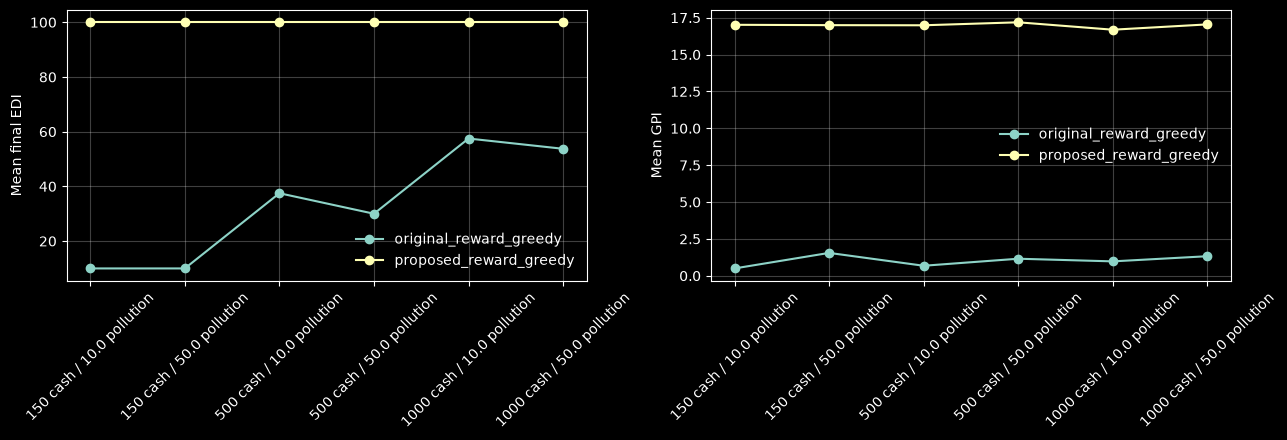

In [21]:
comparison_plot = reward_greedy_summary.copy()

comparison_plot["scenario"] = comparison_plot["starting_cash"].astype(str) + " cash / " + comparison_plot["initial_pollution"].astype(str) + " pollution"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for policy in reward_policies:
    subset = comparison_plot[comparison_plot["policy"] == policy]

    axes[0].plot(subset["scenario"], subset["final_EDI"], marker="o", label=policy)
    axes[1].plot(subset["scenario"], subset["mean_GPI"], marker="o", label=policy)

axes[0].set_ylabel("Mean final EDI")
axes[1].set_ylabel("Mean GPI")

for axis in axes:
    axis.tick_params(axis="x", rotation=45)
    axis.grid(alpha=0.25)
    axis.legend(frameon=False)

plt.tight_layout()
plt.show()

### Findings from the cash and pollution comparison

Across the 30 reward-greedy scenarios (six cash/pollution combinations, five seeds each), the original-reward controller reached EDI 100 in 0 of 30 episodes; the proposed-reward controller reached EDI 100 and survived in 30 of 30. The original controller's mean final EDI ranged from 10 to 57.5 and mean GPI from 0.497 to 1.550. The proposed controller's mean final EDI was 100 in every scenario, mean GPI ranged from 16.687 to 17.189, and peak pressure ranged from 0.290 to 0.431. It spent about 14,460 to 16,795 currency on mitigation, versus 20,040 to 39,335 for the original-reward controller. This is a clear development-versus-pollution tradeoff rather than a zero-pollution outcome.

The low-cash/high-pollution case is informative: with 150 starting currency and 50-unit initial stocks, the proposed controller reached EDI 100 in all five seeds, survived, and had mean GPI 16.996, peak pressure 0.431, and mitigation spending 14,772. The original-reward controller stayed at mean EDI 10, with mean GPI 1.550 and mitigation spending 20,040. The high starting stock fell below the 0.50 pressure line after the initial state; no episode failed.

The hand-written fixed policies show the tradeoff is not automatic. Sequential growth then prevention reached EDI 100 at starting cash 1,000 even from 50-unit pollution, but peak pressure reached 0.918. The threshold-adaptive policy held peak pressure near 0.431 in that case but reached mean EDI 60. The proposed-reward greedy rule combined EDI 100 with peak pressure 0.431 in the same scenario. Across all tested policies and scenarios, no episode hit the environmental failure limit.

For the three hand-written policies, original and proposed reward totals are two scores on the same action trajectories. Their environment outcomes are therefore identical by design. The reward-greedy comparison is the behavioral test: under this non-learning one-step controller, the proposed reward changed the chosen actions toward more development while keeping measured pollution moderate. This does not show that a learned agent will reproduce the behavior.